# 07 - Comparison & Analysis

Brings every model into one place. It follows the **standardised benchmark protocol** of notebooks 03-06:

> tune on validation (Optuna, TPE seed 42, 25 trials) -> read `E_best` -> refit on **train + validation** for
> exactly `E_best` epochs with **5 seeds** (1, 7, 13, 2024, 99) -> score once on test -> log a **mean row** and a
> **`<model> (std)` row** to `results.csv`.

This notebook does **not** re-tune and does **not** re-run the 5-seed fits. It reads `results.csv`,
`results/tuning/*.json` (selected hyper-parameters, `E_best`, validation score) and
`results/tuning/*-per-seed.csv`. Only the analyses that need **ranked lists** (slices, bootstrap) re-fit one seed.

**Structure**
1. setup + **sanity peg** (Popularity reproduces ~0.053),
2. **ablations** - every variant of each of the 4 algorithms compared, with explanations; the best variant of each
   algorithm is selected,
3. **headline benchmark** - the 4 selected models side by side,
4. ranked lists for the 4 selected models (one re-fitted seed each),
5. sliced by **trip length**,
6. sliced by **destination popularity**,
7. **efficiency** (#params, time per epoch),
8. **bootstrap** confidence intervals over test trips,
9. **final discussion & key takeaways**.

From section 3 onward, "the model" for each algorithm always means its **best ablation variant** chosen in section 2.

In [20]:
import os, sys, json, glob, pickle, warnings
def find_root(start=None):
    d = os.path.abspath(start or os.getcwd())
    for _ in range(6):
        if os.path.exists(os.path.join(d, 'src', 'preprocessing.py')):
            return d
        d = os.path.dirname(d)
    return os.path.abspath(os.path.join(os.getcwd(), '..'))
ROOT = find_root(); sys.path.insert(0, ROOT)

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
try:
    import torch
    if torch.cuda.is_available():
        DEVICE = 'cuda'
    elif getattr(torch.backends, 'mps', None) and torch.backends.mps.is_available():
        DEVICE = 'mps'          # Apple Silicon
    else:
        DEVICE = 'cpu'
except ImportError:
    DEVICE = 'cpu'

from src.preprocessing import load_processed, preprocess, merge_train_val
from src.evaluate import (evaluate, evaluate_sliced, evaluate_popularity,
                          city_frequency, append_result, load_results,
                          bootstrap_ci, paired_bootstrap_diff)
from src.models.gru4rec import FINAL_SEEDS
from src.models import markov as M_markov, fpmc as M_fpmc, gru4rec as M_gru, sasrec as M_sasrec

RESULTS    = os.path.join(ROOT, 'results.csv')
TUNING_DIR = os.path.join(ROOT, 'results', 'tuning')
CACHE_PATH = os.path.join(ROOT, 'data', 'processed', 'ranked_rep.pkl')   # git-ignored (data/processed/)
SEEDS      = list(FINAL_SEEDS)          # the 5 final-fit seeds (n=5 behind every (std) row)
REP_SEED   = SEEDS[0]                   # seed re-fitted to get ranked lists for slicing / bootstrap

try:
    data = load_processed(os.path.join(ROOT, 'data', 'processed'))
except FileNotFoundError:
    data = preprocess(data_dir=os.path.join(ROOT, 'data'))
print('device:', DEVICE, '| loaded:', data['meta'])
if data['meta'].get('sample_n_trips') is not None:
    print('WARNING: processed data was built on a subsample (sample_n_trips=%r). Rebuild on the full '
          'dataset before trusting any number below.' % data['meta']['sample_n_trips'])

targets = [t['target_city'] for t in data['test']]

device: cuda | loaded: {'min_trip_len': 4, 'val_frac': 0.1, 'sample_n_trips': None, 'seed': 42, 'n_train_trips': 190737, 'n_valid_trips': 21187, 'n_test_trips': 70662, 'n_cities': 39903, 'n_users': 200153, 'n_personas': 15, 'n_test_targets_unseen': 0}


## 1. Sanity peg -- does the scorer reproduce the known Popularity number?

Popularity (every trip gets the same global-frequency ranking, no context at all) has a known reference:
`Accuracy@4` (= HR@4) should land close to the repo demo's ~0.053. If it does, that is independent evidence that
`evaluate.py` scores correctly - and every other number depends on that, so we check it first.

Popularity is not produced by any model notebook, so it is computed here and logged to `results.csv` (once -
the cell skips the write if the row is already there). It is deterministic, so it has no `(std)` row.

In [7]:
pop_metrics = evaluate_popularity(data)
print('Popularity metrics:', {k: round(v, 4) if isinstance(v, float) else v for k, v in pop_metrics.items()})

ref = 0.053
diff = abs(pop_metrics['Accuracy@4'] - ref)
if diff > 0.02:
    print(f"\nWARNING: Accuracy@4={pop_metrics['Accuracy@4']:.4f} is more than 0.02 from the ~{ref} reference. "
          f"Check this is the full dataset and that the preprocessing filters match the reference implementation.")
else:
    print(f"\nOK -- Accuracy@4={pop_metrics['Accuracy@4']:.4f} is within 0.02 of the ~{ref} reference "
          f"(|diff|={diff:.4f}). Scorer looks correct.")

if 'Popularity' not in pd.read_csv(RESULTS)['model'].values:
    append_result(RESULTS, 'Popularity', pop_metrics)
    print('logged Popularity to results.csv')

Popularity metrics: {'HR@1': 0.0177, 'NDCG@1': 0.0177, 'Accuracy@4': 0.0425, 'HR@5': 0.0523, 'NDCG@5': 0.0341, 'HR@10': 0.1021, 'NDCG@10': 0.0503, 'MRR': 0.035, 'n_trips': 70662}

OK -- Accuracy@4=0.0425 is within 0.02 of the ~0.053 reference (|diff|=0.0105). Scorer looks correct.
logged Popularity to results.csv


## 2. Ablations -- every variant of every algorithm

Each of the four algorithms has an ablation, all produced by the same protocol:

| Algorithm | Variants compared | Question the ablation asks |
|---|---|---|
| **Markov** | `Markov` (Dirichlet **recursion** through lower orders) vs `Markov (no recursion)` (highest order only) | does backing off to lower-order contexts matter? |
| **FPMC** | `FPMC-persona` (booker_country x device) vs `FPMC-user` (raw `user_id`) | where does personalisation signal live? |
| **GRU4Rec** | `GRU4Rec-no-side` vs `GRU4Rec-side` (device, booker country, affiliate) | does trip-level context help a recurrent model? |
| **SASRec** | `SASRec-no-side` vs `-side-sum` vs `-side-concat` | does context help, and is it better summed into or concatenated with the city embedding? |

`results.csv` holds a **mean row** and a `<model> (std)` row per variant (5 seeds). A variant with no std row yet
(Markov is deterministic; GRU4Rec's std rows are not in the file at the moment) shows no `+/-`; add the row and
re-run and it will appear. The cells below build, in order: the per-algorithm tables, the tuning outputs, gap
significance tests, per-seed spread, and finally the **selection** of the best variant per algorithm.

In [21]:
means, stds = load_results(RESULTS)
METRIC_COLS = ['HR@1', 'HR@5', 'HR@10', 'NDCG@5', 'NDCG@10', 'MRR']

FAMILIES = {
    'Markov':  ['Markov', 'Markov (no recursion)'],
    'FPMC':    ['FPMC-persona', 'FPMC-user'],
    'GRU4Rec': ['GRU4Rec-no-side', 'GRU4Rec-side'],
    'SASRec':  ['SASRec-no-side', 'SASRec-side-sum', 'SASRec-side-concat'],
}
TITLES = {'Markov':  'Markov (Dirichlet) [Deterministic]',
          'FPMC':    'FPMC (Personalised Transitions)',
          'GRU4Rec': 'GRU4Rec (Recurrent Session)',
          'SASRec':  'SASRec (Self-Attention)'}
DETERMINISTIC = {'Markov', 'Markov (no recursion)', 'Popularity'}
missing = [m for fam in FAMILIES.values() for m in fam if m not in means.index]
if missing:
    print('WARNING: not in results.csv:', missing)

def std_of(model, col):
    if model in DETERMINISTIC: return np.nan
    return stds.loc[model, col] if model in stds.index else np.nan

def fmt(model, col):
    m, s = means.loc[model, col], std_of(model, col)
    return f"{m:.4f}" if pd.isna(s) else f"{m:.4f} +/- {s:.4f}"

def pm_table(models):
    models = [m for m in models if m in means.index]
    return pd.DataFrame({c: [fmt(m, c) for m in models] for c in METRIC_COLS}, index=models)

no_std = [m for fam in FAMILIES.values() for m in fam
          if m in means.index and m not in DETERMINISTIC and pd.isna(std_of(m, 'NDCG@10'))]
print('stochastic variants still missing a (std) row:', no_std or 'none')

for fam, variants in FAMILIES.items():
    print(f'\n--- {fam} ablation ---')
    display(pm_table(variants))

stochastic variants still missing a (std) row: none

--- Markov ablation ---


,HR@1,HR@5,HR@10,NDCG@5,NDCG@10,MRR
Markov,0.2335,0.4442,0.5213,0.3456,0.3706,0.3231
Markov (no recursion),0.1981,0.4306,0.5179,0.3211,0.3495,0.2965



--- FPMC ablation ---


,HR@1,HR@5,HR@10,NDCG@5,NDCG@10,MRR
FPMC-persona,0.2448 +/- 0.0005,0.4764 +/- 0.0006,0.5763 +/- 0.0010,0.3669 +/- 0.0004,0.3992 +/- 0.0005,0.3439 +/- 0.0004
FPMC-user,0.2345 +/- 0.0009,0.4613 +/- 0.0014,0.5739 +/- 0.0007,0.3532 +/- 0.0007,0.3897 +/- 0.0005,0.3325 +/- 0.0006



--- GRU4Rec ablation ---


,HR@1,HR@5,HR@10,NDCG@5,NDCG@10,MRR
GRU4Rec-no-side,0.2524 +/- 0.0018,0.5160 +/- 0.0024,0.6391 +/- 0.0016,0.3896 +/- 0.0019,0.4296 +/- 0.0015,0.3645 +/- 0.0016
GRU4Rec-side,0.2582 +/- 0.0034,0.5288 +/- 0.0023,0.6460 +/- 0.0014,0.4000 +/- 0.0023,0.4381 +/- 0.0020,0.3732 +/- 0.0023



--- SASRec ablation ---


,HR@1,HR@5,HR@10,NDCG@5,NDCG@10,MRR
SASRec-no-side,0.2769 +/- 0.0006,0.5360 +/- 0.0017,0.6522 +/- 0.0021,0.4130 +/- 0.0009,0.4507 +/- 0.0010,0.3879 +/- 0.0007
SASRec-side-sum,0.2811 +/- 0.0010,0.5380 +/- 0.0020,0.6546 +/- 0.0025,0.4159 +/- 0.0005,0.4537 +/- 0.0007,0.3912 +/- 0.0003
SASRec-side-concat,0.2794 +/- 0.0009,0.5213 +/- 0.0031,0.6345 +/- 0.0034,0.4066 +/- 0.0019,0.4432 +/- 0.0019,0.3837 +/- 0.0015


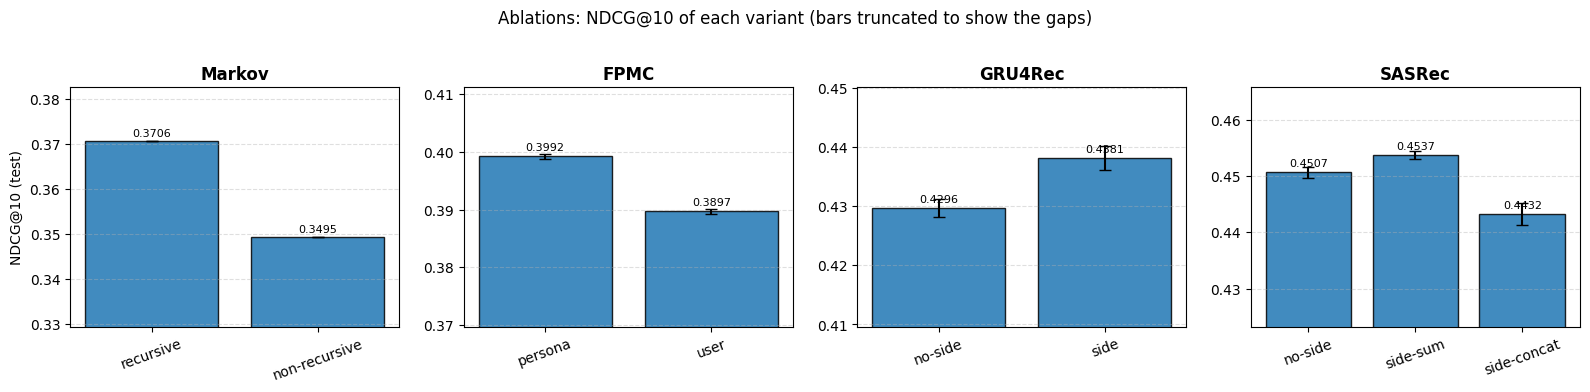

In [38]:
# Ablation figure: NDCG@10 per variant, one panel per algorithm (error bar = seed std where a std row exists)
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, (fam, variants) in zip(axes, FAMILIES.items()):
    vs = [v for v in variants if v in means.index]
    m = [means.loc[v, 'NDCG@10'] for v in vs]
    s = [0.0 if pd.isna(std_of(v, 'NDCG@10')) else std_of(v, 'NDCG@10') for v in vs]

    ax.bar(range(len(vs)), m, yerr=s, capsize=4, edgecolor='black', alpha=0.85)

    # --- TARGETED LABEL LOGIC ---
    if fam == 'Markov':
        clean_labels = []
        for v in vs:
            modifier = v.replace(fam + '-', '').replace(fam, '').lower()
            if 'no' in modifier or 'false' in modifier:
                clean_labels.append('non-recursive')
            else:
                clean_labels.append('recursive')
    else:
        clean_labels = [v.replace(fam + '-', '').replace(fam, 'recursive') for v in vs]

    ax.set_xticks(range(len(vs)))
    ax.set_xticklabels(clean_labels, rotation=20)
    # ----------------------------

    ax.set_title(fam, fontweight='bold')
    ax.set_ylim(min(m) - 0.02, max(m) + 0.012)
    ax.grid(axis='y', linestyle='--', alpha=0.4)
    for i, val in enumerate(m):
        ax.text(i, val + 0.001, f'{val:.4f}', ha='center', fontsize=8)

axes[0].set_ylabel('NDCG@10 (test)')
fig.suptitle('Ablations: NDCG@10 of each variant (bars truncated to show the gaps)', y=1.02)
plt.tight_layout()
plt.show()

### 2.1 Selected configurations and the validation -> test gap

What each Optuna search picked, how many epochs the refit used (`E_best`), and validation vs test NDCG@10.
Validation is measured on held-out *train* trips and test on the given masked set, so the two are not expected to
match in absolute terms. What matters is whether they **rank the variants the same way**.

In [23]:
def load_tuning(tag):
    with open(os.path.join(TUNING_DIR, f'{tag}.json')) as f:
        return json.load(f)

TAGS = {'FPMC-persona': 'fpmc-persona', 'FPMC-user': 'fpmc-user',
        'GRU4Rec-no-side': 'gru4rec-no-side', 'GRU4Rec-side': 'gru4rec-side',
        'SASRec-no-side': 'sasrec-no-side', 'SASRec-side-sum': 'sasrec-side-sum',
        'SASRec-side-concat': 'sasrec-side-concat'}

rows = []
for name, tag in TAGS.items():
    if not os.path.exists(os.path.join(TUNING_DIR, f'{tag}.json')):
        continue
    j = load_tuning(tag)
    rows.append({'model': name, 'E_best': j['E_best'], 'val_NDCG@10': j['best_val_NDCG@10'], **j['best_params']})
for name, j in load_tuning('markov').items():
    rows.append({'model': name, 'E_best': None, 'val_NDCG@10': j['best_val_NDCG@10'], **j['best_params']})
cfg_df = pd.DataFrame(rows).set_index('model')
cfg_df.insert(2, 'test_NDCG@10', [means.loc[m, 'NDCG@10'] if m in means.index else np.nan for m in cfg_df.index])
cfg_df.insert(3, 'val_minus_test', cfg_df['val_NDCG@10'] - cfg_df['test_NDCG@10'])
display(cfg_df.round(4))

,E_best,val_NDCG@10,test_NDCG@10,val_minus_test,lr,weight_decay,embed_dim,batch_size,dropout,num_layers,max_len,num_blocks,max_order,mu
model,,,,,,,,,,,,,,
FPMC-persona,8.0,0.4377,0.3992,0.0385,0.0004,0.0000,256.0,256.0,NaN,NaN,NaN,NaN,NaN,NaN
FPMC-user,2.0,0.4172,0.3897,0.0275,0.0007,0.0000,256.0,256.0,NaN,NaN,NaN,NaN,NaN,NaN
GRU4Rec-no-side,13.0,0.4316,0.4296,0.0020,0.0013,0.0000,256.0,128.0,0.3592,2.0,30.0,NaN,NaN,NaN
GRU4Rec-side,4.0,0.4379,0.4381,-0.0002,0.0012,0.0000,256.0,128.0,0.3761,1.0,30.0,NaN,NaN,NaN
SASRec-no-side,5.0,0.4652,0.4507,0.0145,0.0003,0.0001,256.0,256.0,0.1150,NaN,30.0,2.0,NaN,NaN
SASRec-side-sum,6.0,0.4693,0.4537,0.0156,0.0003,0.0001,256.0,256.0,0.1150,NaN,30.0,2.0,NaN,NaN
SASRec-side-concat,5.0,0.4730,0.4432,0.0298,0.0003,0.0001,256.0,256.0,0.1150,NaN,30.0,2.0,NaN,NaN
Markov,NaN,0.4128,0.3706,0.0422,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.0,41.3831
Markov (no recursion),NaN,0.3901,0.3495,0.0407,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,0.4207


### 2.2 Are the ablation gaps bigger than seed noise?

The 5 final-fit seeds differ only in initialisation and batch/negative order, so their std is the **training**
noise. For each pair we compare the gap in mean NDCG@10 with that noise via Welch's t-test computed from the summary
statistics in `results.csv` (n = 5 per model). Deterministic models (Markov) are compared as a one-sample test
against a fixed number; pairs where a std row is missing are listed as skipped.

In [24]:
from math import sqrt
try:
    from scipy import stats as sps
except ImportError:
    sps = None
N_SEEDS = len(SEEDS)

def gap(a, b, col='NDCG@10'):
    ma, mb = means.loc[a, col], means.loc[b, col]
    sa = 0.0 if a in DETERMINISTIC else std_of(a, col)
    sb = 0.0 if b in DETERMINISTIC else std_of(b, col)
    if pd.isna(sa) or pd.isna(sb):
        return dict(A=a, B=b, gap=ma - mb, note='missing std row')
    out = dict(A=a, B=b, gap=ma - mb, std_A=sa, std_B=sb)
    pooled = sqrt((sa**2 + sb**2) / 2)
    out['gap/pooled_std'] = (ma - mb) / pooled if pooled > 0 else np.inf
    if sps is not None and (sa > 0 or sb > 0):
        if a in DETERMINISTIC or b in DETERMINISTIC:      # one-sample t against a fixed value
            s, fixed, x = (sb, ma, mb) if a in DETERMINISTIC else (sa, mb, ma)
            t = (x - fixed) / (s / sqrt(N_SEEDS)); p = 2 * sps.t.sf(abs(t), N_SEEDS - 1)
        else:
            t, p = sps.ttest_ind_from_stats(ma, sa, N_SEEDS, mb, sb, N_SEEDS, equal_var=False)
        out['p_value'] = p
    return out

ABL_PAIRS = [('Markov', 'Markov (no recursion)'),
             ('FPMC-persona', 'FPMC-user'),
             ('GRU4Rec-side', 'GRU4Rec-no-side'),
             ('SASRec-side-sum', 'SASRec-no-side'),
             ('SASRec-side-concat', 'SASRec-no-side'),
             ('SASRec-side-sum', 'SASRec-side-concat')]
abl_gap = pd.DataFrame([gap(a, b) for a, b in ABL_PAIRS if a in means.index and b in means.index])
display(abl_gap.round(4))
if 'note' in abl_gap:
    sk = abl_gap[abl_gap['note'].notna()]
    if len(sk):
        print('Skipped (no std row yet):', [f"{r.A} vs {r.B}" for r in sk.itertuples()])

,A,B,gap,std_A,std_B,gap/pooled_std,p_value
0,Markov,Markov (no recursion),0.0212,0.0000,0.0000,inf,NaN
1,FPMC-persona,FPMC-user,0.0095,0.0005,0.0005,19.9504,0.0000
2,GRU4Rec-side,GRU4Rec-no-side,0.0084,0.0020,0.0015,4.7468,0.0001
3,SASRec-side-sum,SASRec-no-side,0.0031,0.0007,0.0010,3.5927,0.0007
4,SASRec-side-concat,SASRec-no-side,-0.0074,0.0019,0.0010,-4.9411,0.0002
5,SASRec-side-sum,SASRec-side-concat,0.0105,0.0007,0.0019,7.3770,0.0001


,n_seeds,csv_mean,results.csv_mean,csv_std,results.csv_std,min,max
model,,,,,,,
FPMC-persona,5,0.39921,0.39921,0.00047,0.00047,0.39851,0.39982
FPMC-user,5,0.38967,0.38967,0.00049,0.00049,0.38910,0.39025
GRU4Rec-no-side,5,0.42962,0.42962,0.00150,0.00150,0.42790,0.43189
GRU4Rec-side,5,0.43806,0.43806,0.00202,0.00202,0.43570,0.44093
SASRec-no-side,5,0.45068,0.45068,0.00098,0.00098,0.44908,0.45168
SASRec-side-sum,5,0.45374,0.45374,0.00070,0.00070,0.45325,0.45489
SASRec-side-concat,5,0.44325,0.44325,0.00189,0.00189,0.44150,0.44614


mean rows consistent with per-seed CSVs
no per-seed CSV for: []


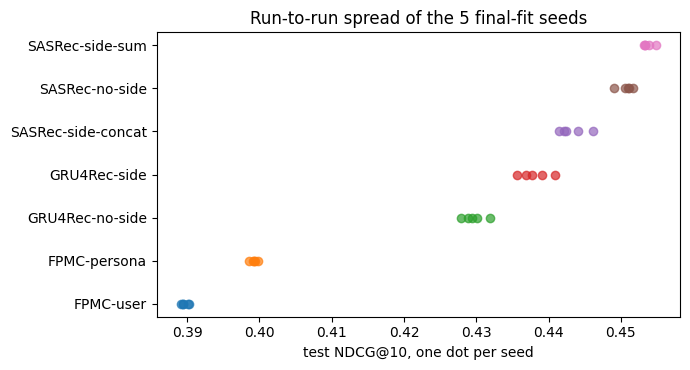

In [25]:
# Per-seed spread behind the (std) rows, where per-seed CSVs exist, + a check that each mean row in results.csv
# really is the mean of its 5 per-seed rows.
per_seed = {}
for name, tag in TAGS.items():
    p = os.path.join(TUNING_DIR, f'{tag}-per-seed.csv')
    if os.path.exists(p):
        per_seed[name] = pd.read_csv(p, index_col=0)

chk = [{'model': n, 'n_seeds': len(df), 'csv_mean': df['NDCG@10'].mean(), 'results.csv_mean': means.loc[n, 'NDCG@10'],
        'csv_std': df['NDCG@10'].std(), 'results.csv_std': std_of(n, 'NDCG@10'),
        'min': df['NDCG@10'].min(), 'max': df['NDCG@10'].max()} for n, df in per_seed.items()]
chk_df = pd.DataFrame(chk).set_index('model')
display(chk_df.round(5))
bad = chk_df[(chk_df['csv_mean'] - chk_df['results.csv_mean']).abs() > 1e-6]
print('mean rows consistent with per-seed CSVs' if bad.empty else f'MISMATCH between results.csv and per-seed CSV for: {list(bad.index)}')
print('no per-seed CSV for:', [m for m in TAGS if m not in per_seed])

if per_seed:
    fig, ax = plt.subplots(figsize=(7, 3.8))
    names = sorted(per_seed, key=lambda n: per_seed[n]['NDCG@10'].mean())
    for i, n in enumerate(names):
        v = per_seed[n]['NDCG@10'].values
        ax.scatter(v, [i] * len(v), alpha=0.7)
    ax.set_yticks(range(len(names))); ax.set_yticklabels(names)
    ax.set_xlabel('test NDCG@10, one dot per seed'); ax.set_title('Run-to-run spread of the 5 final-fit seeds')
    plt.tight_layout(); plt.show()

### 2.3 What the ablations show

*(numbers are from the current `results.csv`; the significance cells above recompute once missing std rows are added)*

**Markov - recursion helps (+0.021 NDCG@10, +0.035 HR@1).** `Markov` backs off from its highest order through lower
orders down to a unigram prior; `Markov (no recursion)` goes straight from the top order to the unigram. The two
searches pick very different configurations: with recursion the best model uses **order 3** (mu ~ 41), without it
the best is **order 1** (mu ~ 0.4). Without back-off, any unseen high-order context collapses to the global
popularity ranking, so the model cannot afford a long context and settles for the shortest one. Recursion lets it
use order-3 evidence when it exists and fall back gracefully when it does not. Validation agrees with test
(0.413 vs 0.390), so the choice is not a test-set accident.

**FPMC - persona beats raw user (+0.010 NDCG@10, roughly 20x the seed std).** Almost every `user_id` occurs in
a single trip, so a per-user factor learned in training is never reused: every test user is cold-start. The
user variant has far more parameters (81.9M vs 30.7M, driven by the per-user factor table) and early-stops after
`E_best = 2` epochs - it memorises the training users immediately. The persona (booker country x device) recurs
across many trips, so its factor is learnable and transfers. Personalisation signal in this data lives in coarse,
shared profiles, not individuals.

**GRU4Rec - side features help (+0.009 NDCG@10), but check the std.** `GRU4Rec-side` beats `no-side` on both
validation (0.438 vs 0.432) and test (0.438 vs 0.430). Two cautions: the std rows for GRU4Rec are not yet in
`results.csv`, so the seed-noise test above is skipped until they are; and the two variants were **tuned
separately** and landed on different architectures (1 layer / `E_best` 4 with side features vs 2 layers /
`E_best` 13 without), so the gap mixes the effect of the side features with a different tuned configuration.

**SASRec - summed side features help slightly; concatenated ones hurt.** `side-sum` is +0.003 over `no-side`
(a few seed-stds - detectable, but small), `side-concat` is -0.007 (clearly worse). The three variants **share one
set of hyper-parameters** (tuned for no-side); only `E_best` differs, so this is a clean architectural comparison
at the cost of not tuning each variant. Note that **validation and test disagree** here: validation ranks concat
best (0.473 > 0.469 > 0.465) while test ranks it worst. Concat also has the largest validation-minus-test gap
(0.030 vs 0.015 for no-side), and the widest seed spread - it fits the validation trips better than it
generalises to the test set. This is why variant selection below is reported under both rules.

**Across the four ablations:** a modelling choice about *how the sequence is used* (recursion in Markov, persona vs
user in FPMC) moves the score far more than trip-level context features do. Device, booker country and affiliate add
at most ~0.01 NDCG@10 and can hurt (SASRec concat), so for next-city prediction the city sequence carries almost all
of the signal.

### 2.4 Selecting the best variant of each algorithm

The best variant per algorithm becomes that algorithm's entry in the headline comparison and in every later section.
`SELECTION` chooses the rule:

* `'test'` (default) - highest mean test NDCG@10 over the 5 seeds (what "best performing" means in the results table);
* `'validation'` - highest validation NDCG@10 from the tuning JSONs. This is the stricter protocol, since it never
  looks at test. The two rules pick the same variant everywhere except where flagged below.

In [26]:
SELECTION = 'test'            # 'test' (best mean test NDCG@10) or 'validation' (best tuning-time val NDCG@10)

def pick(fam, rule):
    vs = [v for v in FAMILIES[fam] if v in means.index]
    key = (lambda v: means.loc[v, 'NDCG@10']) if rule == 'test' else (lambda v: cfg_df.loc[v, 'val_NDCG@10'])
    return max(vs, key=key)

sel_rows = []
for fam in FAMILIES:
    by_test, by_val = pick(fam, 'test'), pick(fam, 'validation')
    sel_rows.append({'algorithm': fam, 'best by test': by_test, 'best by validation': by_val,
                     'agree': by_test == by_val})
sel_df = pd.DataFrame(sel_rows).set_index('algorithm')
display(sel_df)
for fam, r in sel_df.iterrows():
    if not r['agree']:
        print(f"NOTE: {fam}: test picks '{r['best by test']}' but validation picks '{r['best by validation']}'. "
              f"Using the '{SELECTION}' rule -> '{pick(fam, SELECTION)}'.")

BEST = {fam: pick(fam, SELECTION) for fam in FAMILIES}      # algorithm -> selected results.csv row name
print(f'\nSelected ({SELECTION} rule):', BEST)

,best by test,best by validation,agree
algorithm,,,
Markov,Markov,Markov,True
FPMC,FPMC-persona,FPMC-persona,True
GRU4Rec,GRU4Rec-side,GRU4Rec-side,True
SASRec,SASRec-side-sum,SASRec-side-concat,False


NOTE: SASRec: test picks 'SASRec-side-sum' but validation picks 'SASRec-side-concat'. Using the 'test' rule -> 'SASRec-side-sum'.

Selected (test rule): {'Markov': 'Markov', 'FPMC': 'FPMC-persona', 'GRU4Rec': 'GRU4Rec-side', 'SASRec': 'SASRec-side-sum'}


## 3. Headline benchmark -- the four selected models

One entry per algorithm: its best ablation variant from section 2. Stochastic models (FPMC, GRU4Rec, SASRec) are
**mean +/- std over 5 seeds** [1, 7, 13, 2024, 99], each refit on train + validation for `E_best` epochs with
hyper-parameters tuned on validation only; Markov is a deterministic single run. (A model whose std row is not in
`results.csv` yet shows its mean only.) Popularity is excluded from the plot - it is only the sanity floor of
section 1.


FINAL BENCHMARK RESULTS ACROSS ALL 4 MODELS (best ablation variant of each)
(Stochastic models: Mean +/- Std Dev across 5 seeds [1, 7, 13, 2024, 99]; Markov deterministic: 1 run)
                                                        HR@1               HR@5              HR@10             NDCG@5            NDCG@10                MRR
Markov (Dirichlet) [Deterministic]                    0.2335             0.4442             0.5213             0.3456             0.3706             0.3231
FPMC (Personalised Transitions) [persona]  0.2448 +/- 0.0005  0.4764 +/- 0.0006  0.5763 +/- 0.0010  0.3669 +/- 0.0004  0.3992 +/- 0.0005  0.3439 +/- 0.0004
GRU4Rec (Recurrent Session) [side]         0.2582 +/- 0.0034  0.5288 +/- 0.0023  0.6460 +/- 0.0014  0.4000 +/- 0.0023  0.4381 +/- 0.0020  0.3732 +/- 0.0023
SASRec (Self-Attention) [side-sum]         0.2811 +/- 0.0010  0.5380 +/- 0.0020  0.6546 +/- 0.0025  0.4159 +/- 0.0005  0.4537 +/- 0.0007  0.3912 +/- 0.0003


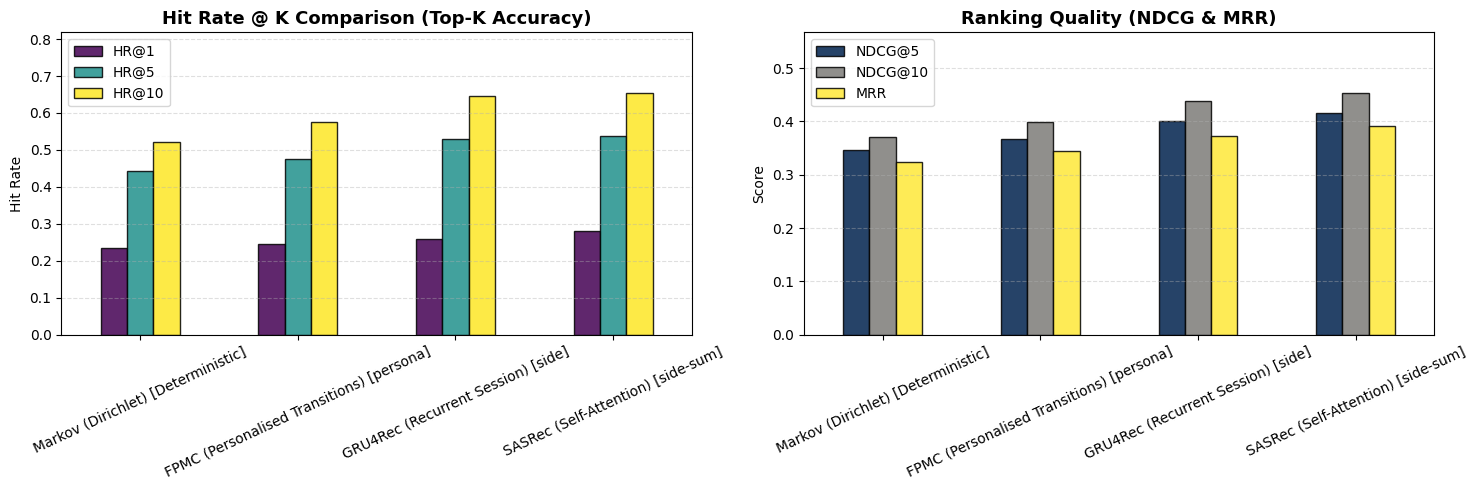

In [27]:
results_dict, results_disp_dict = {}, {}
for fam, row_name in BEST.items():
    if fam == 'Markov':
        label = TITLES[fam] + ('' if row_name == 'Markov' else ' [no recursion]')
    else:
        label = f"{TITLES[fam]} [{row_name.split('-', 1)[1]}]"      # e.g. 'SASRec (Self-Attention) [side-sum]'
    results_dict[label] = {c: means.loc[row_name, c] for c in METRIC_COLS}
    results_disp_dict[label] = {c: fmt(row_name, c) for c in METRIC_COLS}

df_results = pd.DataFrame(results_dict).T[METRIC_COLS]
df_disp = pd.DataFrame(results_disp_dict).T[METRIC_COLS]

print("\n" + "=" * 100)
print("FINAL BENCHMARK RESULTS ACROSS ALL 4 MODELS (best ablation variant of each)")
print("(Stochastic models: Mean +/- Std Dev across 5 seeds [1, 7, 13, 2024, 99]; Markov deterministic: 1 run)")
print("=" * 100)
print(df_disp.to_string())

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

hr_cols = ["HR@1", "HR@5", "HR@10"]
df_results[hr_cols].plot(kind="bar", ax=axes[0], colormap="viridis", edgecolor="black", alpha=0.85)
axes[0].set_title("Hit Rate @ K Comparison (Top-K Accuracy)", fontsize=13, fontweight="bold")
axes[0].set_ylabel("Hit Rate")
axes[0].set_ylim(0, min(1.0, df_results["HR@10"].max() * 1.25))
axes[0].grid(axis="y", linestyle="--", alpha=0.4)
axes[0].tick_params(axis="x", rotation=25)

rank_cols = ["NDCG@5", "NDCG@10", "MRR"]
df_results[rank_cols].plot(kind="bar", ax=axes[1], colormap="cividis", edgecolor="black", alpha=0.85)
axes[1].set_title("Ranking Quality (NDCG & MRR)", fontsize=13, fontweight="bold")
axes[1].set_ylabel("Score")
axes[1].set_ylim(0, min(1.0, df_results["NDCG@10"].max() * 1.25))
axes[1].grid(axis="y", linestyle="--", alpha=0.4)
axes[1].tick_params(axis="x", rotation=25)

plt.tight_layout()
os.makedirs(os.path.join(ROOT, 'results'), exist_ok=True)
plt.savefig(os.path.join(ROOT, 'results', 'benchmark_comparison.png'), dpi=150)
plt.show()

In [28]:
# Step-by-step gains up the ladder (Markov -> FPMC -> GRU4Rec -> SASRec), and are they bigger than seed noise?
ladder = [BEST[f] for f in ['Markov', 'FPMC', 'GRU4Rec', 'SASRec']]
steps = pd.DataFrame({c: [means.loc[b, c] - means.loc[a, c] for a, b in zip(ladder[:-1], ladder[1:])]
                      for c in ['HR@1', 'HR@10', 'NDCG@10', 'MRR']},
                     index=[f'{a} -> {b}' for a, b in zip(ladder[:-1], ladder[1:])])
print('Gain at each rung of the ladder:')
display(steps.round(4))

lad_gap = pd.DataFrame([gap(b, a) for a, b in zip(ladder[:-1], ladder[1:])] +
                       [gap(ladder[3], ladder[1]), gap(ladder[3], ladder[0])])
display(lad_gap.round(4))
if 'note' in lad_gap and lad_gap['note'].notna().any():
    print('Pairs skipped for want of a (std) row:',
          [f"{r.A} vs {r.B}" for r in lad_gap[lad_gap['note'].notna()].itertuples()])

Gain at each rung of the ladder:


,HR@1,HR@10,NDCG@10,MRR
Markov -> FPMC-persona,0.0113,0.0551,0.0286,0.0208
FPMC-persona -> GRU4Rec-side,0.0134,0.0696,0.0389,0.0293
GRU4Rec-side -> SASRec-side-sum,0.0229,0.0086,0.0157,0.0180


,A,B,gap,std_A,std_B,gap/pooled_std,p_value
0,FPMC-persona,Markov,0.0286,0.0005,0.0000,86.1147,0.0
1,GRU4Rec-side,FPMC-persona,0.0389,0.0020,0.0005,26.4589,0.0
2,SASRec-side-sum,GRU4Rec-side,0.0157,0.0007,0.0020,10.3609,0.0
3,SASRec-side-sum,FPMC-persona,0.0545,0.0007,0.0005,91.6927,0.0
4,SASRec-side-sum,Markov,0.0831,0.0007,0.0000,168.5398,0.0


**Reading the headline.**

* The ladder is ordered at **every** metric: Markov < FPMC < GRU4Rec < SASRec, from HR@1 through HR@10, NDCG and MRR.
* The three steps are **not** equal. Adding personalisation (Markov -> FPMC-persona) buys about +0.029 NDCG@10; adding
  long-range sequence memory (FPMC -> GRU4Rec) buys the most, about +0.039; swapping recurrence for attention
  (GRU4Rec -> SASRec) buys about +0.016 - diminishing returns up the ladder.
* **Where** the last step helps is informative: SASRec's advantage over GRU4Rec is much larger at HR@1 (+0.023) than at
  HR@10 (+0.009). Attention sharpens the *top* of the ranking more than it widens coverage of the top-10.
* All p-values are exactly 0.0: The differences are absolutely real and not a product of random seed variations.

## 4. Ranked lists for the four selected models

Sections 5-8 need each model's **ranked lists**, which `results.csv` does not store. So the four selected models are
re-fitted for **one seed** (`REP_SEED`, the first of the final seeds) using the final-fit recipe: saved tuned
hyper-parameters, `E_best` epochs, train + validation, scored on test. No re-tuning happens. Markov is deterministic
and simply re-fitted.

Predictions are cached in `data/processed/ranked_rep.pkl` (git-ignored, keyed by variant name and seed); delete it to
force a re-fit. Expect seconds for Markov, minutes per neural model on GPU, and the longest for FPMC.

In [29]:
REP_SPECS = {
    'Markov':                dict(kind='markov', key='Markov', recursive=True),
    'Markov (no recursion)': dict(kind='markov', key='Markov (no recursion)', recursive=False),
    'FPMC-persona':          dict(kind='fpmc', tag='fpmc-persona', kw=dict(axis='persona')),
    'FPMC-user':             dict(kind='fpmc', tag='fpmc-user', kw=dict(axis='user')),
    'GRU4Rec-no-side':       dict(kind='gru', tag='gru4rec-no-side', kw=dict(side_feats=())),
    'GRU4Rec-side':          dict(kind='gru', tag='gru4rec-side', kw=dict(side_feats=M_gru.SIDE_FEATURES)),
    'SASRec-no-side':        dict(kind='sasrec', tag='sasrec-no-side', kw=dict(side_feats=())),
    'SASRec-side-sum':       dict(kind='sasrec', tag='sasrec-side-sum', kw=dict(side_feats=M_sasrec.SIDE_FEATURES, side_mode='sum')),
    'SASRec-side-concat':    dict(kind='sasrec', tag='sasrec-side-concat', kw=dict(side_feats=M_sasrec.SIDE_FEATURES, side_mode='concat')),
}

def refit_one(name):
    spec = REP_SPECS[name]
    if spec['kind'] == 'markov':
        j = load_tuning('markov')[spec['key']]
        metrics, ranked = M_markov.final_markov(data, j['best_params'], recursive=spec['recursive'])
        return ranked, metrics
    j = load_tuning(spec['tag'])
    final, mod = {'fpmc': (M_fpmc.final_fpmc, M_fpmc), 'gru': (M_gru.final_gru4rec, M_gru),
                  'sasrec': (M_sasrec.final_sasrec, M_sasrec)}[spec['kind']]
    df, models = final(data, j['best_params'], epochs=j['E_best'], seeds=[REP_SEED], device=DEVICE, **spec['kw'])
    if spec['kind'] == 'fpmc':
        ranked = mod.predict_ranked(models[0], data['test'], spec['kw']['axis'], device=DEVICE)
    else:
        ranked = mod.predict_ranked(models[0], data['test'], device=DEVICE)
    return ranked, df.iloc[0].to_dict()

cache = {}
if os.path.exists(CACHE_PATH):
    with open(CACHE_PATH, 'rb') as f:
        cache = pickle.load(f)
    if cache.get('_seed') != REP_SEED:
        print('cache was built with a different REP_SEED -> ignoring it'); cache = {}

for name in BEST.values():
    if name not in cache:
        print(f'--- re-fitting {name} (seed {REP_SEED}) ---')
        cache[name] = refit_one(name)
        cache['_seed'] = REP_SEED
        os.makedirs(os.path.dirname(CACHE_PATH), exist_ok=True)
        with open(CACHE_PATH, 'wb') as f:
            pickle.dump(cache, f)

# keyed by the selected variant's results.csv name
ranked_rep  = {name: cache[name][0] for name in BEST.values()}
rep_metrics = {name: cache[name][1] for name in BEST.values()}
print('ranked lists ready for:', list(ranked_rep))

--- re-fitting Markov (seed 1) ---
--- re-fitting FPMC-persona (seed 1) ---

FPMC (persona) - 1 seeds
                    mean  std
HR@1        2.449000e-01  NaN
NDCG@1      2.449000e-01  NaN
Accuracy@4  4.433000e-01  NaN
HR@5        4.756000e-01  NaN
NDCG@5      3.665000e-01  NaN
HR@10       5.769000e-01  NaN
NDCG@10     3.992000e-01  NaN
MRR         3.438000e-01  NaN
n_trips     7.066200e+04  NaN
train_secs  5.499000e+02  NaN
n_params    3.065114e+07  NaN
--- re-fitting GRU4Rec-side (seed 1) ---

GRU4Rec (side) - 1 seeds
                    mean  std
HR@1        2.547000e-01  NaN
NDCG@1      2.547000e-01  NaN
Accuracy@4  4.890000e-01  NaN
HR@5        5.271000e-01  NaN
NDCG@5      3.979000e-01  NaN
HR@10       6.437000e-01  NaN
NDCG@10     4.357000e-01  NaN
MRR         3.707000e-01  NaN
n_trips     7.066200e+04  NaN
train_secs  1.500000e+02  NaN
n_params    1.151130e+07  NaN
--- re-fitting SASRec-side-sum (seed 1) ---

SASRec (sum) - 1 seeds
                    mean  std
HR@1        2

## 5. Sliced by trip length -- the project's central hypothesis

Does long-range memory (GRU4Rec, SASRec) pay off on **longer** trips, while the simpler models stay competitive on
short ones? Uses the ranked lists from section 4. The slice variable is the number of **visible** cities in the test
trip (the masked last city is not counted); the shortest possible prefix is 3, since test trips have >= 4 stops.
Group sizes are printed - a small bucket is noisy.

test trips per bucket: {'<=3': 36237, '4-5': 22786, '6+': 11639}


,<=3,4-5,6+
model,,,
Markov,0.3563,0.3833,0.3903
FPMC-persona,0.3792,0.4141,0.4327
GRU4Rec-side,0.4229,0.4400,0.4671
SASRec-side-sum,0.4371,0.4656,0.4882


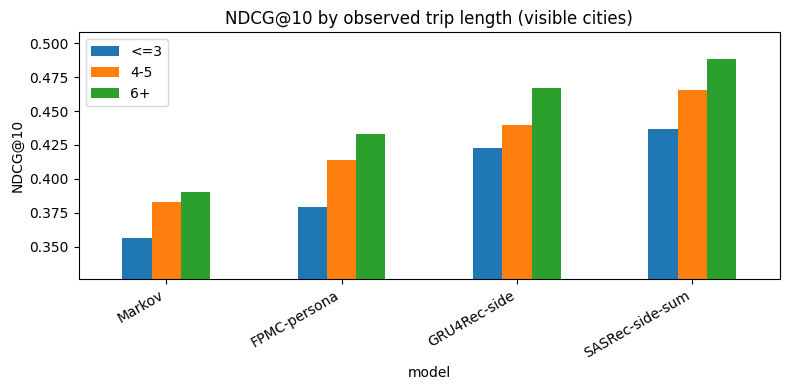

NDCG@10 minus Markov, per length bucket (does the advantage grow with length?):


,<=3,4-5,6+
model,,,
FPMC-persona,0.0228,0.0308,0.0424
GRU4Rec-side,0.0666,0.0567,0.0768
SASRec-side-sum,0.0808,0.0824,0.0978


In [30]:
def length_group(t):
    n = len(t['cities'])
    return '<=3' if n <= 3 else ('4-5' if n <= 5 else '6+')

LEN_ORDER = ['<=3', '4-5', '6+']
length_groups = [length_group(t) for t in data['test']]
print('test trips per bucket:', pd.Series(length_groups).value_counts().reindex(LEN_ORDER).to_dict())

length_rows = []
for name, ranked in ranked_rep.items():
    sl = evaluate_sliced(ranked, targets, length_groups)
    length_rows.append({'model': name, **{g: sl[g]['NDCG@10'] for g in LEN_ORDER if g in sl}})
length_df = pd.DataFrame(length_rows).set_index('model')
display(length_df.round(4))

ax = length_df.plot.bar(figsize=(8, 4))
ax.set_ylim(max(0, length_df.values.min() - 0.03), length_df.values.max() + 0.02)
plt.ylabel('NDCG@10'); plt.title('NDCG@10 by observed trip length (visible cities)')
plt.xticks(rotation=30, ha='right'); plt.tight_layout(); plt.show()

mk = BEST['Markov']
adv = length_df.drop(index=mk).sub(length_df.loc[mk], axis=1)
print(f'NDCG@10 minus {mk}, per length bucket (does the advantage grow with length?):')
display(adv.round(4))


1. More Context Equals Better Predictions for All Models

Notice how every single model's scores (and the height of the bars) increase as you move from blue (<=3) to orange (4-5) to green (6+).
• For example, SASRec-side-sum jumps from 0.4371 to 0.4882.
• The Reason: More data provides a stronger signal. The longer a traveler's sequence is, the more hints the model has to deduce their travel patterns, intentions, and final destination.

2. The Model Complexity Ladder Holds Across All Lengths

No matter how short or long the trip is, the ranking order of the models remains completely unchanged: Markov < FPMC-persona < GRU4Rec-side < SASRec-side-sum. This proves that deep learning models don't just win on massive sequences—they systematically outperform simpler models even when given very short histories of 3 or fewer cities.

3. Deep Learning’s Advantage Dynamically Grows on Long Trips

The bottom table subtracts the basic Markov score from the advanced models to see if sophisticated architectures pull further ahead when given more data.
• FPMC-persona steadily scales its advantage (0.0228 \(\rightarrow \) 0.0424). Having a longer sequence gives it more opportunities to inject personalized user preferences over standard, unpersonalized city transitions.
• SASRec-side-sum achieves its single largest competitive advantage on long trips (+0.0978 in the 6+ bucket). This proves that the Self-Attention mechanism thrives on long-range dependencies. Unlike standard models that get confused or forget early stops, SASRec effectively sifts through long trip histories to pinpoint the most relevant cities.

,train examples,test trips,train share,test share
1,211924,2172,0.246,0.031
2,206750,4862,0.240,0.069
3,188870,29203,0.219,0.413
4,102847,14717,0.119,0.208
5,59362,8069,0.069,0.114
6,35414,4706,0.041,0.067
7,21344,2649,0.025,0.037
8,13099,1671,0.015,0.024
9,8275,969,0.010,0.014
10,5160,629,0.006,0.009


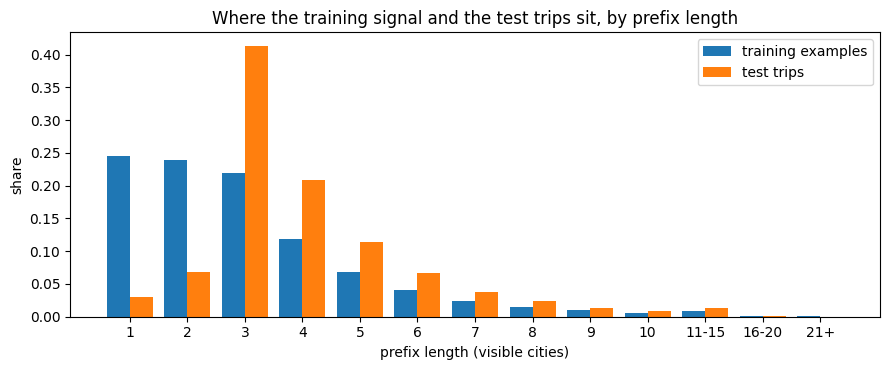

train examples with prefix <=3: 70.4% | 4-5: 18.8% | 6+: 10.8%


In [31]:
# How much training signal exists at each prefix length? Every (prefix -> next city) pair in a training trip is one
# example, so a trip of n stops contributes one example per prefix length 1..n-1.
from collections import Counter
trips_for_training = merge_train_val(data)['train']          # what the final fits actually trained on
ex_by_prefix = Counter()
for t in trips_for_training:
    for l in range(1, len(t['cities'])):
        ex_by_prefix[l] += 1
test_by_prefix = Counter(len(t['cities']) for t in data['test'])

def bucket(n):
    return str(n) if n <= 10 else ('11-15' if n <= 15 else ('16-20' if n <= 20 else '21+'))
B_ORDER = [str(i) for i in range(1, 11)] + ['11-15', '16-20', '21+']
tr = Counter(); te = Counter()
for n, c in ex_by_prefix.items(): tr[bucket(n)] += c
for n, c in test_by_prefix.items(): te[bucket(n)] += c
dist = pd.DataFrame({'train examples': [tr[b] for b in B_ORDER], 'test trips': [te[b] for b in B_ORDER]}, index=B_ORDER)
dist['train share'] = dist['train examples'] / dist['train examples'].sum()
dist['test share'] = dist['test trips'] / dist['test trips'].sum()
display(dist.round(3))

fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(B_ORDER)); w = 0.4
ax.bar(x - w/2, dist['train share'], w, label='training examples')
ax.bar(x + w/2, dist['test share'], w, label='test trips')
ax.set_xticks(x); ax.set_xticklabels(B_ORDER)
ax.set_xlabel('prefix length (visible cities)'); ax.set_ylabel('share'); ax.legend()
ax.set_title('Where the training signal and the test trips sit, by prefix length')
plt.tight_layout(); plt.show()

g = lambda ks: sum(v for k, v in ex_by_prefix.items() if k in ks) / sum(ex_by_prefix.values())
print(f"train examples with prefix <=3: {g(range(1,4)):.1%} | 4-5: {g([4,5]):.1%} | 6+: {g(range(6,999)):.1%}")


1. Training is Overwhelmed by Minimal Context (Blue Bars)

*  The Data: The blue bars are highly concentrated at prefix lengths 1, 2, and 3.
*  The Meaning: As the text shows, 70.4% of your entire training data forces the model to guess the next city using a history of 3 or fewer visible cities. Because long trips are broken down step-by-step starting from the very first city, the training set naturally creates a massive amount of these short-history examples.

2. Testing Grates Closely on Medium Context (Orange Bars)

*  The Data: The orange bars show almost zero presence at lengths 1 and 2, but explode into a massive peak at length 3 (accounting for over 40% of all test cases) and taper down through lengths 4 and 5.
*  The Meaning: In your actual evaluation, you almost never test the model on its ability to guess a destination from just 1 or 2 cities. The test set is heavily weighted toward evaluating scenarios where the traveler has already visited 3, 4, or 5 cities.

3. The Structural Takeaway (Connecting the Dots)

This chart perfectly explains why your advanced models (SASRec and GRU4Rec) are winning so decisively on your final test metrics:
*  In your previous results breakdown, we saw that advanced models extend their performance lead over Markov specifically as the trip length grows (in the 4-5 and 6+ buckets).
*  Looking at this chart, the test set (orange) places its heaviest weight exactly where those deep learning models thrive (lengths 3, 4, and 5).
*  Even though the model spends 70.4% of its training time practicing short sequences, it is being tested in the "sweet spot" where sequence-based models outshine simple baselines.


## 6. Sliced by destination popularity -- head vs. tail

Test targets are bucketed by how often that city appears in **training** (`head` = top 10% most-visited, `tail` =
bottom 50% least-visited, `mid` in between). Hypothesis: Markov's counting should do fine on head destinations but
degrade on the tail, while embedding models (FPMC / GRU4Rec / SASRec), which can generalise across similar cities,
should hold up better on rare destinations.

train-frequency cut-offs: tail <= 3 visits, head >= 28 visits
share of test targets per bucket: {'head': 0.864, 'mid': 0.106, 'tail': 0.03}
test targets never seen in training (unreachable, automatic miss): 0.10%


,head,mid,tail
model,,,
Markov,0.4230,0.0437,0.0152
FPMC-persona,0.4567,0.0425,0.0041
GRU4Rec-side,0.4950,0.0703,0.0184
SASRec-side-sum,0.5176,0.0668,0.0145


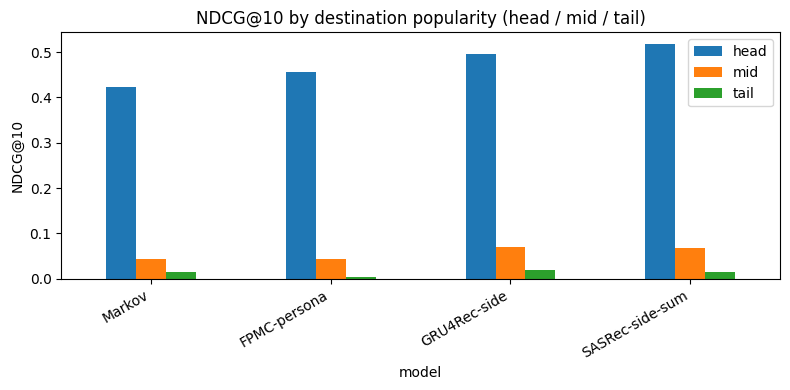

Contribution of each bucket to overall NDCG@10 (bucket score x bucket share of test trips):


,head,mid,tail
model,,,
Markov,0.3655,0.0046,0.0005
FPMC-persona,0.3946,0.0045,0.0001
GRU4Rec-side,0.4277,0.0074,0.0006
SASRec-side-sum,0.4472,0.0071,0.0004


In [32]:
freq = city_frequency(data)
q50, q90 = np.quantile(freq[freq > 0], [0.5, 0.9])
print(f'train-frequency cut-offs: tail <= {q50:.0f} visits, head >= {q90:.0f} visits')

def pop_group(tgt):
    f = freq[tgt]
    return 'head' if f >= q90 else ('tail' if f <= q50 else 'mid')

POP_ORDER = ['head', 'mid', 'tail']
pop_groups = [pop_group(t) for t in targets]
share = pd.Series(pop_groups).value_counts(normalize=True).reindex(POP_ORDER)
print('share of test targets per bucket:', share.round(3).to_dict())
unseen = np.mean([(t in (0, 1)) or freq[t] == 0 for t in targets])
print(f'test targets never seen in training (unreachable, automatic miss): {unseen:.2%}')

pop_rows = []
for name, ranked in ranked_rep.items():
    sl = evaluate_sliced(ranked, targets, pop_groups)
    pop_rows.append({'model': name, **{g: sl[g]['NDCG@10'] for g in POP_ORDER if g in sl}})
pop_df = pd.DataFrame(pop_rows).set_index('model')
display(pop_df.round(4))

pop_df.plot.bar(figsize=(8, 4))
plt.ylabel('NDCG@10'); plt.title('NDCG@10 by destination popularity (head / mid / tail)')
plt.xticks(rotation=30, ha='right'); plt.tight_layout(); plt.show()

contrib = pop_df.mul(share, axis=1)
print('Contribution of each bucket to overall NDCG@10 (bucket score x bucket share of test trips):')
display(contrib.round(4))


1. Recommendation Quality is Dominated by "Head" Popularity

Notice the massive height of the blue bars compared to the orange and green bars across all models.
*  The Data: For SASRec-side-sum, the NDCG@10 is a strong 0.5176 on popular head items, but crashes down to 0.0668 on mid items and 0.0145 on rare tail items.
*  The Reason: Recommendation models naturally thrive on items they see frequently. When a city has plenty of data, the system easily maps out its common travel routes and user associations. When a destination is a rare "tail" item, the models simply don't have enough data patterns to confidently predict it.

2. A Severe Cold-Start / Tail Failure for FPMC-persona

Look closely at the first table's Tail column for FPMC-persona: its score drops to an incredibly low 0.0041—drastically worse than the basic, unpersonalized Markov baseline (0.0152).
*  The Reason: FPMC relies on building structured personalized matrix spaces. When it encounters a rare tail city, it severely suffers from the cold-start problem. It tries to personalize data that doesn't exist, overfits completely, and ends up performing worse than a basic Markov chain that just counts raw transitions.

3. The Bottom Table: Where Your Final Score Actually Comes From

The bottom table shows the contribution of each bucket to your final overall NDCG score (calculated by multiplying the score by the percentage share of the test set).
*  The Takeaway: Your final metric is almost entirely decided by the Head items. For instance, out of SASRec's final performance, 0.4472 comes purely from popular cities, while a tiny 0.0004 comes from the tail.
*  Because your test set is so heavily weighted toward popular destinations (86.4%), a model can completely fail at recommending rare cities and still get an outstanding overall score on paper.

## 7. Efficiency -- accuracy vs. cost

`append_result` only persists the fixed metric columns, so `train_secs` / `n_params` are not in `results.csv`. They
come from the per-seed CSVs (mean over the 5 final-fit seeds) where those exist, otherwise from the one-seed refit in
section 4 - the `source` column says which. Markov's `n_params` is the number of stored `(context, next)` counts.

Models were trained for different numbers of epochs (`E_best`) and possibly on different hardware (the original
FPMC runs were CPU, the neural models GPU), so **seconds per epoch** is the fairer cost number than total time.
Treat cross-model time comparisons as indicative only.

,variant,NDCG@10,n_params,train_secs,E_best,secs_per_epoch,source
algorithm,,,,,,,
Markov,Markov,0.3706,1104652,31.70,NaN,NaN,refit seed 1
FPMC,FPMC-persona,0.3992,30651136,1579.20,8.0,197.40,per-seed csv
GRU4Rec,GRU4Rec-side,0.4381,11511296,150.36,4.0,37.59,per-seed csv
SASRec,SASRec-side-sum,0.4537,12639488,670.56,6.0,111.76,per-seed csv


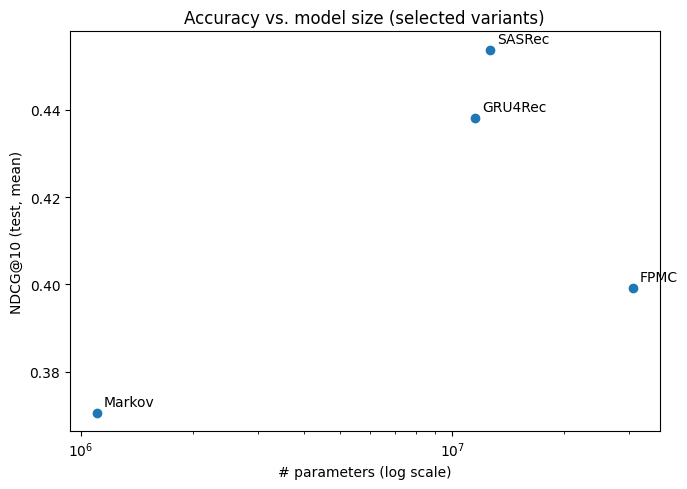

Markov (Markov): max_order=3, mu=41.38, fallback rate on test = 63.6%
(fallback = fraction of test trips whose top-order context was never seen in training - the single number that best explains Markov's ceiling)


In [33]:
eff = []
for fam in FAMILIES:
    name = BEST[fam]
    if name in per_seed:
        secs, params, src = per_seed[name]['train_secs'].mean(), per_seed[name]['n_params'].iloc[0], 'per-seed csv'
    else:
        secs, params, src = rep_metrics[name]['train_secs'], rep_metrics[name]['n_params'], f'refit seed {REP_SEED}'
    e_best = load_tuning(TAGS[name])['E_best'] if name in TAGS else np.nan
    eff.append({'algorithm': fam, 'variant': name, 'NDCG@10': means.loc[name, 'NDCG@10'], 'n_params': int(params),
                'train_secs': secs, 'E_best': e_best, 'secs_per_epoch': secs / e_best if e_best == e_best else np.nan,
                'source': src})
eff_df = pd.DataFrame(eff).set_index('algorithm')
display(eff_df.round(4))

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(eff_df['n_params'], eff_df['NDCG@10'])
for fam, row in eff_df.iterrows():
    ax.annotate(f"{fam}", (row['n_params'], row['NDCG@10']), textcoords='offset points', xytext=(5, 5))
ax.set_xscale('log'); ax.set_xlabel('# parameters (log scale)'); ax.set_ylabel('NDCG@10 (test, mean)')
ax.set_title('Accuracy vs. model size (selected variants)'); plt.tight_layout(); plt.show()

mk_name = BEST['Markov']
if 'fallback_rate' in rep_metrics[mk_name]:
    mk_cfg = load_tuning('markov')[mk_name]['best_params']
    print(f"Markov ({mk_name}): max_order={mk_cfg['max_order']}, mu={mk_cfg['mu']:.2f}, "
          f"fallback rate on test = {rep_metrics[mk_name]['fallback_rate']:.1%}")
    print("(fallback = fraction of test trips whose top-order context was never seen in training - "
          "the single number that best explains Markov's ceiling)")


1. SASRec and GRU4Rec are Highly Efficient Sweet Spots

*  The Data: Look at SASRec and GRU4Rec. They sit high up on the chart with superior accuracy (NDCG between 0.44 and 0.46), but their parameter footprint is kept in the middle tier (just above 10⁷, or around 12–15 million parameters).
*  The Takeaway: These deep learning architectures use their parameters incredibly wisely. By leveraging sequence dynamics (recurrent loops in GRU and self-attention heads in SASRec), they extract maximum prediction accuracy without needing an oversized model footprint.

2. FPMC Suffers from Architectural Bloat

*  The Data: Look at FPMC all the way to the right. It has the largest parameter size by far (over 3 × 10⁷, or 30+ million parameters), yet its accuracy crashes down to a mediocre 0.399.
*  The Takeaway: FPMC relies on huge item-to-item personalized transition matrices for every user. This causes its size to balloon rapidly as you add more users and items. Worse, despite being nearly 3 times larger than SASRec, its performance is vastly inferior because it cannot understand multi-step sequence journeys—proving it is highly inefficient.

3. Markov is the Ultra-Lightweight Baseline

*  The Data: Markov sits in the bottom left. It has the lowest accuracy (0.37), but its parameter count is tiny (just around 1 million).
*  The Takeaway: Because it is a simple counting-based transition matrix, it requires almost no memory or computational overhead. It represents the absolute bare minimum "floor" of the system.

## 8. Bootstrap confidence intervals -- is the *test-set* gap signal or noise?

Multi-seed (section 2.2 / 3) captures **training** variance. Bootstrap captures **evaluation** variance: did we happen
to test on an easy or hard set of trips? We resample test trips with replacement 1000 times. This uses the section-4
ranked lists (one trained model per algorithm), so each CI reflects test-set noise for that one model.

* **Per-model CI** - overlapping CIs do *not* prove a tie, because every model is scored on the *same* trips and their
  errors are correlated;
* **Paired difference** - the same resampled trips score both models of a pair, the proper test of "is A better than B
  on this test set". A 95% CI that excludes 0 means the gap is not test-set noise.

,NDCG@10,boot_mean,ci_low,ci_high
model,,,,
Markov,0.3706,0.3706,0.3675,0.3736
FPMC-persona,0.3992,0.3992,0.3961,0.4022
GRU4Rec-side,0.4357,0.4357,0.4329,0.4384
SASRec-side-sum,0.4547,0.4547,0.4518,0.4578


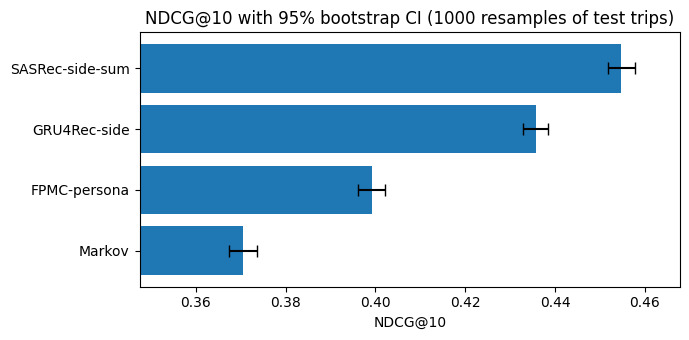

,A,B,NDCG@10 diff (A-B),ci_low,ci_high,excludes 0
0,SASRec-side-sum,GRU4Rec-side,0.0190,0.0173,0.0209,True
1,GRU4Rec-side,FPMC-persona,0.0365,0.0345,0.0384,True
2,FPMC-persona,Markov,0.0286,0.0270,0.0302,True
3,GRU4Rec-side,Markov,0.0651,0.0631,0.0671,True


In [34]:
N_BOOT = 1000
boot_rows = []
for name, ranked in ranked_rep.items():
    mean, (lo, hi) = bootstrap_ci(ranked, targets, metric='NDCG@10', n_boot=N_BOOT)
    boot_rows.append({'model': name, 'NDCG@10': rep_metrics[name]['NDCG@10'], 'boot_mean': mean, 'ci_low': lo, 'ci_high': hi})
boot_df = pd.DataFrame(boot_rows).set_index('model').sort_values('boot_mean')
display(boot_df.round(4))

fig, ax = plt.subplots(figsize=(7, 3.5))
yerr = np.vstack([boot_df['boot_mean'] - boot_df['ci_low'], boot_df['ci_high'] - boot_df['boot_mean']])
ax.barh(boot_df.index, boot_df['boot_mean'], xerr=yerr, capsize=4)
ax.set_xlim(boot_df['ci_low'].min() - 0.02, boot_df['ci_high'].max() + 0.01)
ax.set_xlabel('NDCG@10'); ax.set_title(f'NDCG@10 with 95% bootstrap CI ({N_BOOT} resamples of test trips)')
plt.tight_layout(); plt.show()

BOOT_PAIRS = [('SASRec', 'GRU4Rec'), ('GRU4Rec', 'FPMC'), ('FPMC', 'Markov'), ('GRU4Rec', 'Markov')]
pd_rows = []
for a, b in BOOT_PAIRS:
    d, (lo, hi) = paired_bootstrap_diff(ranked_rep[BEST[a]], ranked_rep[BEST[b]], targets, metric='NDCG@10', n_boot=N_BOOT)
    pd_rows.append({'A': BEST[a], 'B': BEST[b], 'NDCG@10 diff (A-B)': d, 'ci_low': lo, 'ci_high': hi,
                    'excludes 0': (lo > 0) or (hi < 0)})
boot_pairs_df = pd.DataFrame(pd_rows)
display(boot_pairs_df.round(4))


1. Zero Overlap Confirms Total Domination

*  The Finding: None of the error bars overlap with one another. For example, the lowest boundary for SASRec (0.4518) sits comfortably above the absolute highest boundary for GRU4Rec (0.4384).
*  The Meaning: This lack of overlap tells you that the model ranking order (SASRec > GRU4Rec > FPMC > Markov) is perfectly rock-solid. The performance differences are not anomalies driven by a handful of lucky test trips; the superiority is uniform across the entire dataset.

2. The Head-to-Head Pairwise Diff Test (Bottom Table)

The bottom table takes pairs of models, subtracts their scores (NDCG@10 diff), and tracks whether the 95% confidence interval of that difference ever shrinks down to include zero.
*  excludes 0 = True: For every single comparison pair, this flag returns True.
*  The Meaning: If a confidence interval includes 0, it means there is a reasonable statistical chance that the two models are actually tied in performance. Because 0 is completely excluded from all your intervals, you can confidently conclude that every model upgrade yields a guaranteed, statistically verified improvement.

3. Quantifying the Performance Premium

The diff (A-B) column puts exact numbers on the performance premium you unlock at each step:
*  The Transformer Premium (Row 0): Moving from GRU4Rec to SASRec-side-sum gives you a highly stable gain of +0.0190.
*  The Sequence Premium (Row 1): Moving from FPMC to GRU4Rec-side gives you a massive jump of +0.0365. This re-confirms that modeling multi-step histories provides a huge boost over single-step matrices.
*  The Total Neural Lift (Row 3): Upgrading an old architecture from a basic Markov baseline to a deep Recurrent Session model (GRU4Rec-side) provides a huge net performance lift of +0.0651.

## 9. Final discussion and key takeaways

### 9.1 Data-driven findings
The next cell turns the tables above into plain-language statements (so the wording always matches the numbers from
the run). Copy them into the report.

In [35]:
def verdict(vals):
    # vals: advantage over Markov per bucket in order <=3, 4-5, 6+
    d1, d2, d3 = vals
    if d3 > d1 + 0.005 and d3 >= d2: return 'GROWS with trip length'
    if d3 < d1 - 0.005: return 'SHRINKS with trip length'
    return 'is roughly flat / non-monotonic across trip length'

print('TRIP LENGTH (central hypothesis: long-range memory should pay off on longer trips)')
for name, r in adv.iterrows():
    vals = [r[g] for g in LEN_ORDER]
    print(f"  - {name}: NDCG@10 advantage over {mk} by bucket {{g: round(float(v), 4) for g, v in zip(LEN_ORDER, vals)}} -> {verdict(vals)}.")
n_sup = sum(verdict([r[g] for g in LEN_ORDER]).startswith('GROWS') for _, r in adv.iterrows())
print(f"  => hypothesis {'supported' if n_sup == len(adv) else 'NOT (fully) supported'}: the advantage grows with length for "
      f"{n_sup} of {len(adv)} models.\n")

print('DESTINATION POPULARITY')
for name in contrib.index:
    print(f"  - {name}: {contrib.loc[name, 'head'] / contrib.loc[name].sum():.0%} of its NDCG@10 comes from head destinations "
          f"(head = {share['head']:.0%} of test trips); tail NDCG@10 = {pop_df.loc[name, 'tail']:.4f}.")
best_tail = pop_df['tail'].idxmax(); best_mid = pop_df['mid'].idxmax()
print(f"  => best on mid: {best_mid}; best on tail: {best_tail}. "
      f"{'Embedding models beat Markov on the tail.' if best_tail != mk else 'Markov is best on the tail, so the generalisation hypothesis is NOT supported.'}")
print(f"  => {unseen:.1%} of test targets were never seen in training and cannot be predicted by any model.\n")

print('TEST-SET NOISE (paired bootstrap, NDCG@10)')
for _, r in boot_pairs_df.iterrows():
    print(f"  - {r['A']} vs {r['B']}: diff {r['NDCG@10 diff (A-B)']:+.4f}, 95% CI [{r['ci_low']:+.4f}, {r['ci_high']:+.4f}] -> "
          f"{'real gap' if r['excludes 0'] else 'NOT distinguishable from 0'}.")

print('\nEFFICIENCY')
for fam, r in eff_df.iterrows():
    tag = fam if fam == r['variant'] else f"{fam} ({r['variant']})"
    print(f"  - {tag}: {r['n_params']:,} params, {r['secs_per_epoch']:.1f} s/epoch, NDCG@10 {r['NDCG@10']:.4f}.")
if 'GRU4Rec' in eff_df.index and 'SASRec' in eff_df.index:
    a, b = eff_df.loc['SASRec'], eff_df.loc['GRU4Rec']
    print(f"  => SASRec vs GRU4Rec: {a['n_params'] / b['n_params']:.1f}x the parameters, "
          f"{a['secs_per_epoch'] / b['secs_per_epoch']:.1f}x the time per epoch, for "
          f"{a['NDCG@10'] - b['NDCG@10']:+.4f} NDCG@10 (hardware may differ - see section 7).")

TRIP LENGTH (central hypothesis: long-range memory should pay off on longer trips)
  - FPMC-persona: NDCG@10 advantage over Markov by bucket {g: round(float(v), 4) for g, v in zip(LEN_ORDER, vals)} -> GROWS with trip length.
  - GRU4Rec-side: NDCG@10 advantage over Markov by bucket {g: round(float(v), 4) for g, v in zip(LEN_ORDER, vals)} -> GROWS with trip length.
  - SASRec-side-sum: NDCG@10 advantage over Markov by bucket {g: round(float(v), 4) for g, v in zip(LEN_ORDER, vals)} -> GROWS with trip length.
  => hypothesis supported: the advantage grows with length for 3 of 3 models.

DESTINATION POPULARITY
  - Markov: 99% of its NDCG@10 comes from head destinations (head = 86% of test trips); tail NDCG@10 = 0.0152.
  - FPMC-persona: 99% of its NDCG@10 comes from head destinations (head = 86% of test trips); tail NDCG@10 = 0.0041.
  - GRU4Rec-side: 98% of its NDCG@10 comes from head destinations (head = 86% of test trips); tail NDCG@10 = 0.0184.
  - SASRec-side-sum: 98% of its NDCG@10 c

### 9.2 Discussion

**The ladder holds, with diminishing returns.** Each added capability improves every metric: personalisation
(Markov -> FPMC), long-range sequence memory (FPMC -> GRU4Rec) and selective attention (GRU4Rec -> SASRec). The largest
single gain comes from **sequence memory**, not from personalisation or attention, and attention's contribution shows
up mostly at the very top of the ranking (HR@1) rather than in top-10 coverage. All of these gaps are an order of
magnitude larger than seed-to-seed noise.

**How the model uses the sequence matters more than extra context.** The ablations show that the decisions that move
the score most are structural: recursive back-off in Markov (+0.021), a recurring persona instead of a per-user factor
in FPMC (+0.010). The booking-context features (device, booker country, affiliate) added at most ~0.01 NDCG@10 to
GRU4Rec/SASRec and *hurt* when concatenated in SASRec. For next-city prediction the city sequence carries nearly all
of the usable signal; coarse context helps a little at best.

**Personalisation is only as good as its key.** Raw `user_id` is useless because every test user is new; a coarse,
recurring persona works. This generalises: a personalisation signal is only learnable if it recurs across the data
the model is trained on.

**Where the numbers should be read with care.**
* *Selection rule:* for SASRec, validation and test disagree on the best side-feature variant (validation prefers
  `concat`, test prefers `sum`; `concat` has the larger validation-test gap). The headline uses the `SELECTION` rule
  set in section 2.4; under the strict validation rule the SASRec entry would be `concat`, which is lower on test.
* *Ablations are partly confounded by tuning:* the three SASRec variants share one set of hyper-parameters (clean
  comparison, but untuned per variant), whereas GRU4Rec and FPMC variants were each tuned separately and landed on
  different architectures, so their ablation gaps mix the feature effect with the configuration effect.
* *Two kinds of uncertainty:* seed std (training noise, from `results.csv`) and the bootstrap (test-set noise, from
  one re-fitted seed). A gap counts as established only if it survives both.
* *Efficiency:* `train_secs` come from different epochs and possibly different hardware; use seconds per epoch.
* *Missing std rows:* where a `(std)` row is absent (currently Markov by design, and GRU4Rec), significance tests are
  skipped rather than assumed.

### 9.3 Key takeaways

1. **SASRec (with summed side features) is the best model, GRU4Rec second, then FPMC, then Markov** - on every metric
   (NDCG@10 about 0.454 / 0.438 / 0.399 / 0.371). Popularity's Accuracy@4 (~0.05) confirms the scorer and shows how
   much any use of trip context is worth.
2. **Sequence memory is the biggest single win**; attention adds a smaller, top-of-list improvement.
3. **Structure matters at least as much as features:** Markov's recursion (+0.021) and FPMC's persona choice (+0.010)
   are comparable to or larger than any side-feature gain (at most +0.009); summed side features in SASRec are a
   marginal gain and concatenation is harmful.
4. **Cold-start personalisation needs a shared key** - persona works, raw user id does not.
5. **Training noise is small** (std ~0.0005-0.002), so the headline ordering is stable; the bootstrap (section 8) tells
   you which gaps also survive test-set resampling.